In [6]:
import numpy as np
import pandas as pd
from pathlib import Path

root = Path.home() / "Desktop/Chooser_Option_Research"

data = pd.read_csv(
    root / "02_Data/processed/W02_Feature_Dataset.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

# Future 20-trading-day realized volatility
horizon = 20

data["target_rv_20d"] = (
    data["log_return_1d"]
    .rolling(horizon)
    .std()
    .shift(-horizon)
    * np.sqrt(252)
)

# Last observation required to compute each target
data["target_end"] = data["Date"].shift(-horizon)

# Conservatively lag Treasury features by one day
data["rate_lag1"] = data["DGS6MO"].shift(1)
data["spread_lag1"] = data["term_spread"].shift(1)

ml_features = [
    "return_5d",
    "return_20d",
    "volatility_5d",
    "volatility_20d",
    "volume_ratio",
    "VIX_Close",
    "rate_lag1",
    "spread_lag1"
]

model_df = data.dropna(
    subset=ml_features + ["target_rv_20d", "target_end"]
).copy()

# Chronological split; targets must finish inside each period
train = model_df[
    (model_df["Date"] < "2023-01-01") &
    (model_df["target_end"] < "2023-01-01")
]

valid = model_df[
    (model_df["Date"] >= "2023-01-01") &
    (model_df["Date"] < "2024-01-01") &
    (model_df["target_end"] < "2024-01-01")
]

test = model_df[
    (model_df["Date"] >= "2024-01-01") &
    (model_df["target_end"] <= "2024-12-31")
]

print("Training:", train.shape)
print("Validation:", valid.shape)
print("Testing:", test.shape)

assert len(train) > 0 and len(valid) > 0 and len(test) > 0

Training: (1218, 27)
Validation: (230, 27)
Testing: (232, 27)


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_train = train[ml_features]
y_train = train["target_rv_20d"]

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=7,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

rows = []

for name, sample in [("Validation", valid), ("Test", test)]:

    actual = sample["target_rv_20d"]

    predictions = {
        "Historical 20D": sample["volatility_20d"],
        "Random Forest": model.predict(sample[ml_features])
    }

    for method, predicted in predictions.items():
        rows.append({
            "Period": name,
            "Model": method,
            "MAE (pp)": mean_absolute_error(actual, predicted) * 100,
            "RMSE (pp)": np.sqrt(
                mean_squared_error(actual, predicted)
            ) * 100
        })

performance_df = pd.DataFrame(rows)

display(performance_df.round(3))

Note: you may need to restart the kernel to use updated packages.


,Period,Model,MAE (pp),RMSE (pp)
0,Validation,Historical 20D,6.081,8.455
1,Validation,Random Forest,6.201,8.143
2,Test,Historical 20D,9.306,12.482
3,Test,Random Forest,7.452,10.558


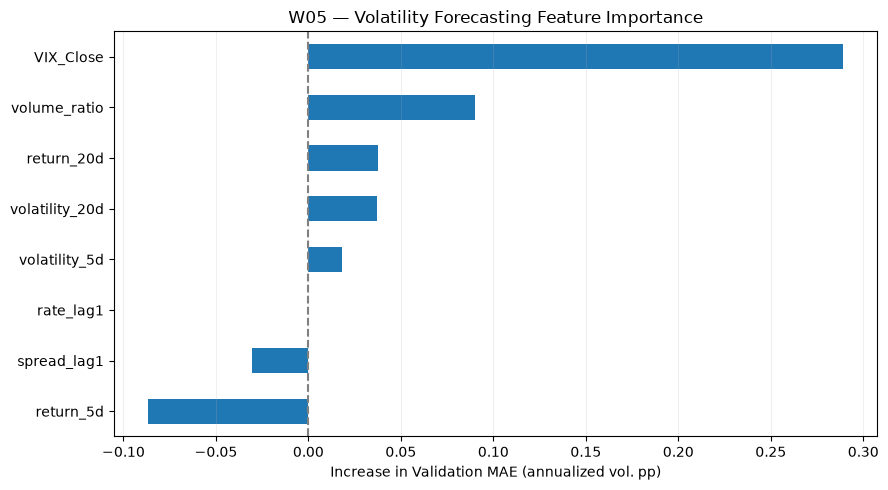

Feature importance figure saved.


In [8]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

importance_result = permutation_importance(
    model,
    valid[ml_features],
    valid["target_rv_20d"],
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance = pd.Series(
    importance_result.importances_mean * 100,
    index=ml_features
).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

importance.plot.barh(ax=ax)

ax.axvline(0, linestyle="--", color="gray")
ax.set_xlabel("Increase in Validation MAE (annualized vol. pp)")
ax.set_title("W05 — Volatility Forecasting Feature Importance")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W05_Volatility_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance figure saved.")

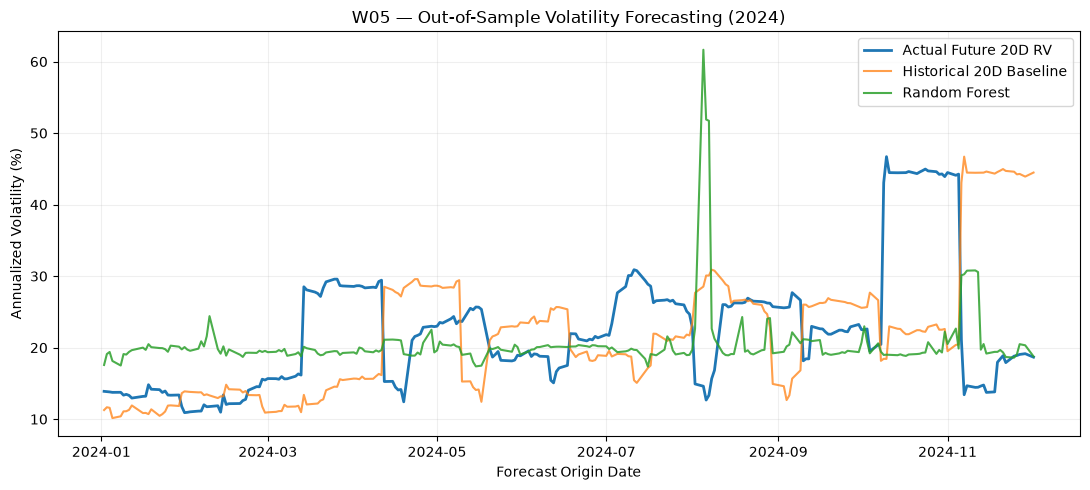

In [9]:
# W05 Step 4: Out-of-Sample Volatility Predictions

test_results = test[["Date", "target_rv_20d"]].copy()

test_results["Historical_20d"] = test["volatility_20d"].to_numpy()
test_results["Random_Forest"] = model.predict(test[ml_features])

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    test_results["Date"],
    test_results["target_rv_20d"] * 100,
    label="Actual Future 20D RV",
    linewidth=2
)

ax.plot(
    test_results["Date"],
    test_results["Historical_20d"] * 100,
    label="Historical 20D Baseline",
    alpha=0.75
)

ax.plot(
    test_results["Date"],
    test_results["Random_Forest"] * 100,
    label="Random Forest",
    alpha=0.85
)

ax.set_title("W05 — Out-of-Sample Volatility Forecasting (2024)")
ax.set_xlabel("Forecast Origin Date")
ax.set_ylabel("Annualized Volatility (%)")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

fig.savefig(
    fig_dir / "W05_Volatility_Forecast_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Inspect largest daily moves in 2024

check_2024 = data.loc[
    data["Date"].dt.year == 2024,
    ["Date", "log_return_1d", "VIX_Close"]
].copy()

check_2024["abs_return"] = (
    check_2024["log_return_1d"].abs()
)

display(
    check_2024.nlargest(10, "abs_return").round(4)
)

/var/folders/ln/jcfj_dfd3wsfk53_r56tcqn40000gn/T/ipykernel_17044/1406478633.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  check_2024.nlargest(10, "abs_return").round(4)


,Date,log_return_1d,VIX_Close,abs_return
1703,2024-11-06,0.1093,16.27,0.1093
1559,2024-04-12,-0.0669,17.31,0.0669
1662,2024-09-10,-0.0533,19.08,0.0533
1585,2024-05-20,-0.0460,12.15,0.0460
1704,2024-11-07,-0.0442,15.20,0.0442
1685,2024-10-11,0.0434,20.46,0.0434
1636,2024-08-02,-0.0433,23.39,0.0433
1680,2024-10-04,0.0349,19.21,0.0349
1732,2024-12-18,-0.0341,27.62,0.0341
1625,2024-07-18,-0.0323,15.93,0.0323


In [11]:
# Find the largest Random Forest forecast in 2024
peak_idx = test_results["Random_Forest"].idxmax()

print("Largest Random Forest prediction:")

display(
    test_results.loc[
        [peak_idx],
        ["Date", "Random_Forest",
         "target_rv_20d", "Historical_20d"]
    ]
)

# Inspect the input features on that date
print("Input features at prediction peak:")

display(
    test.loc[[peak_idx], ["Date"] + ml_features]
)

Largest Random Forest prediction:


,Date,Random_Forest,target_rv_20d,Historical_20d
1637,2024-08-05,0.616574,0.146046,0.285371


Input features at prediction peak:


,Date,return_5d,return_20d,volatility_5d,volatility_20d,volume_ratio,VIX_Close,rate_lag1,spread_lag1
1637,2024-08-05,-0.075646,-0.050056,0.37,0.285371,1.392955,38.57,0.0488,-0.0055


In [12]:
# Diagnostic: sensitivity to VIX on August 5

peak_row = test.loc[[peak_idx], ml_features].copy()

vix_scenarios = [20.0, 25.0, 30.0, 38.57]

results = []

for vix in vix_scenarios:
    scenario = peak_row.copy()
    scenario["VIX_Close"] = vix

    prediction = model.predict(scenario)[0]

    results.append({
        "VIX": vix,
        "RF Forecast (%)": prediction * 100
    })

display(pd.DataFrame(results).round(2))

,VIX,RF Forecast (%)
0,20.00,21.27
1,25.00,40.40
2,30.00,53.88
3,38.57,61.66
